In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as  sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans,DBSCAN
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set(style="whitegrid")
RANDOM_STATE=42

In [ ]:
df = pd.read_csv("/content/online_retail_II.csv")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df.head(10)



,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [ ]:
print(df.info())
print()
print("Shape :",df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB
None

Shape : (1067371, 8)


In [ ]:
df = df.dropna(subset=["Customer ID"])

df["Invoice"]=df["Invoice"].astype(str)
df=df[~df["Invoice"].str.startswith("C")]

df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

df["Customer ID"] = df["Customer ID"].astype(int)

df["TotalPrice"] = df["Quantity"] * df["Price"]
print("No. of Total Customers : ",df["Customer ID"].nunique())


No. of Total Customers :  5878


## RFM TABLE

In [ ]:
snapshot_date=df["InvoiceDate"].max()+pd.Timedelta(days=1)

rfm=df.groupby("Customer ID").agg(
    Recency = ("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency = ("Invoice","nunique"),
    Monetary = ("TotalPrice","sum"),
)

rfm.describe().round(1)


,Recency,Frequency,Monetary
count,5878.0,5878.0,5878.0
mean,201.3,6.3,3018.6
std,209.3,13.0,14737.7
min,1.0,1.0,3.0
25%,26.0,1.0,348.8
50%,96.0,3.0,898.9
75%,380.0,7.0,2307.1
max,739.0,398.0,608821.6


In [ ]:
print("Skewness before:\n", rfm.skew().round(2),"\n")
rfm_log=np.log1p(rfm)
print()
print("Skewness after log:\n", rfm_log.skew().round(2),"\n")

Skewness before:
 Recency       0.89
Frequency    12.64
Monetary     25.31
dtype: float64 


Skewness after log:
 Recency     -0.49
Frequency    1.00
Monetary     0.27
dtype: float64 



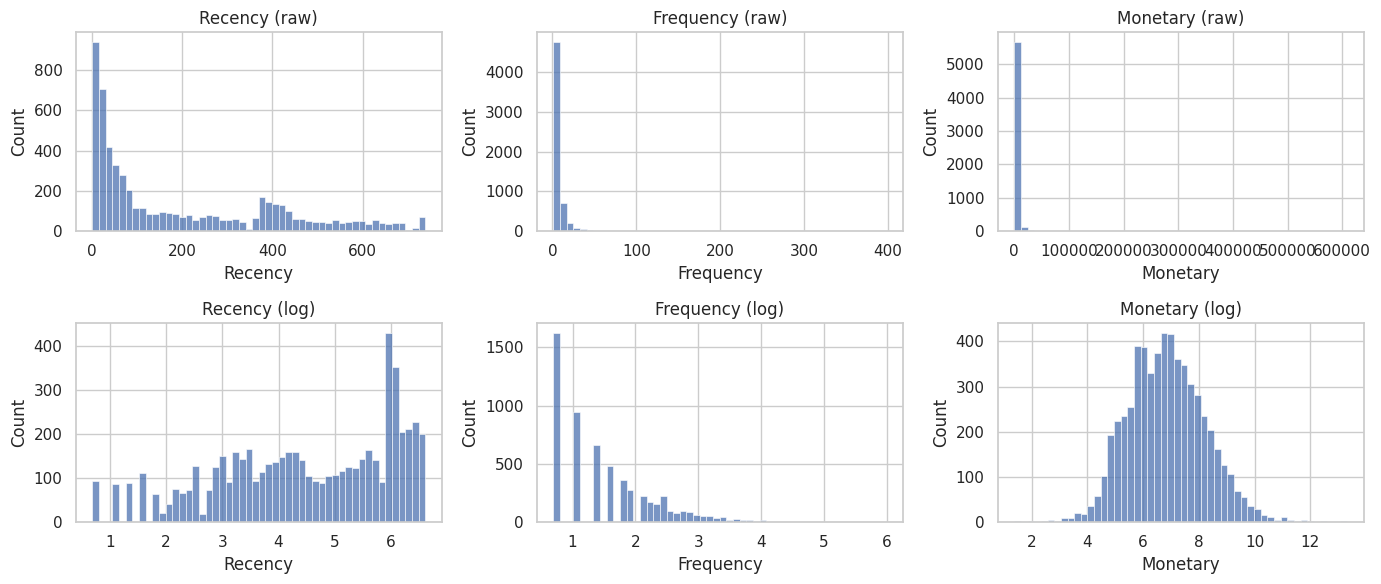

In [ ]:
scaler=StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for i, col in enumerate(rfm.columns):
    sns.histplot(rfm[col], bins=50, ax=axes[0, i]).set_title(f"{col} (raw)")
    sns.histplot(rfm_log[col], bins=50, ax=axes[1, i]).set_title(f"{col} (log)")
plt.tight_layout()

# PCA

In [ ]:
pca_full = PCA().fit(X_scaled)

print("Explained Variance ratio:",pca_full.explained_variance_ratio_.round(3))
print("Cumulative:",pca_full.explained_variance_ratio_.cumsum().round(3))
print()

pca = PCA(n_components = 0.90, random_state=43)
X_pca = pca.fit_transform(X_scaled)

print("Components kept:", pca.n_components_)
print()

loadings = pd.DataFrame(pca.components_.T, index=rfm.columns, columns=[f"PC{i+1}" for i in range(pca.n_components_)])
print(loadings.round(2))


Explained Variance ratio: [0.764 0.188 0.049]
Cumulative: [0.764 0.951 1.   ]

Components kept: 2

            PC1   PC2
Recency   -0.50  0.86
Frequency  0.62  0.30
Monetary   0.60  0.42


# K-Means

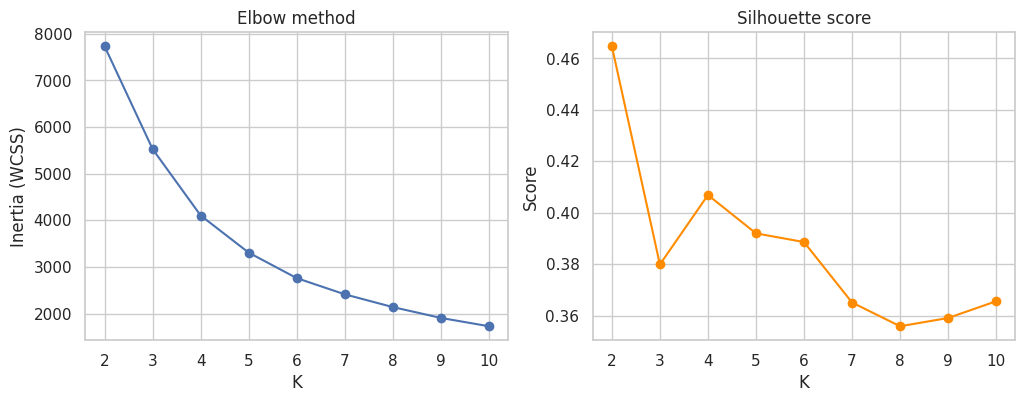

The right K:  2


In [ ]:
k_range = range(2,11)
inertias,sil_scores = [],[]

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=43)
    labels = kmeans.fit_predict(X_pca)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_range, inertias, "o-"); ax[0].set(title="Elbow method", xlabel="K", ylabel="Inertia (WCSS)")
ax[1].plot(k_range, sil_scores, "o-", color="darkorange"); ax[1].set(title="Silhouette score", xlabel="K", ylabel="Score")
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print("The right K: ",best_k)

In [ ]:
K=best_k
kmeans=KMeans(n_clusters=K,random_state=43)
rfm["KMeans"] = kmeans.fit_predict(X_pca)
print(rfm["KMeans"].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(X_pca, rfm["KMeans"]), 3))


KMeans
0    3567
1    2311
Name: count, dtype: int64
Silhouette: 0.465


# DBSCAN

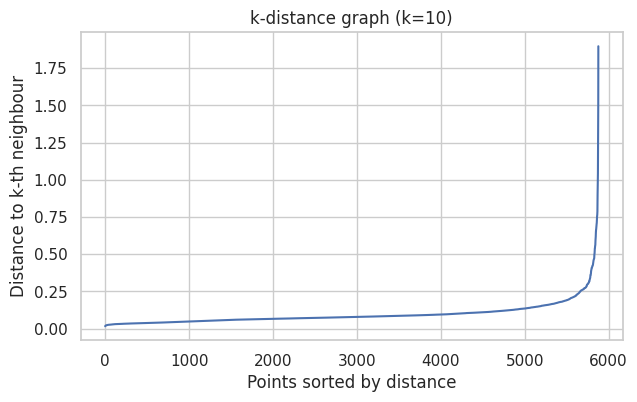

eps ≈ 0.161
DBSCAN clusters: 5 | noise points: 351 (6.0%)


In [ ]:
min_samples = 10


nn = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distances, _ = nn.kneighbors(X_pca)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist); plt.title(f"k-distance graph (k={min_samples})")
plt.xlabel("Points sorted by distance"); plt.ylabel("Distance to k-th neighbour"); plt.show()

eps = float(np.percentile(k_dist, 90))
print("eps ≈", round(eps, 3))

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
rfm["DBSCAN"] = dbscan.fit_predict(X_pca)

n_clusters = len(set(rfm["DBSCAN"])) - (1 if -1 in rfm["DBSCAN"].values else 0)
n_noise = (rfm["DBSCAN"] == -1).sum()
print(f"DBSCAN clusters: {n_clusters} | noise points: {n_noise} ({n_noise/len(rfm):.1%})")

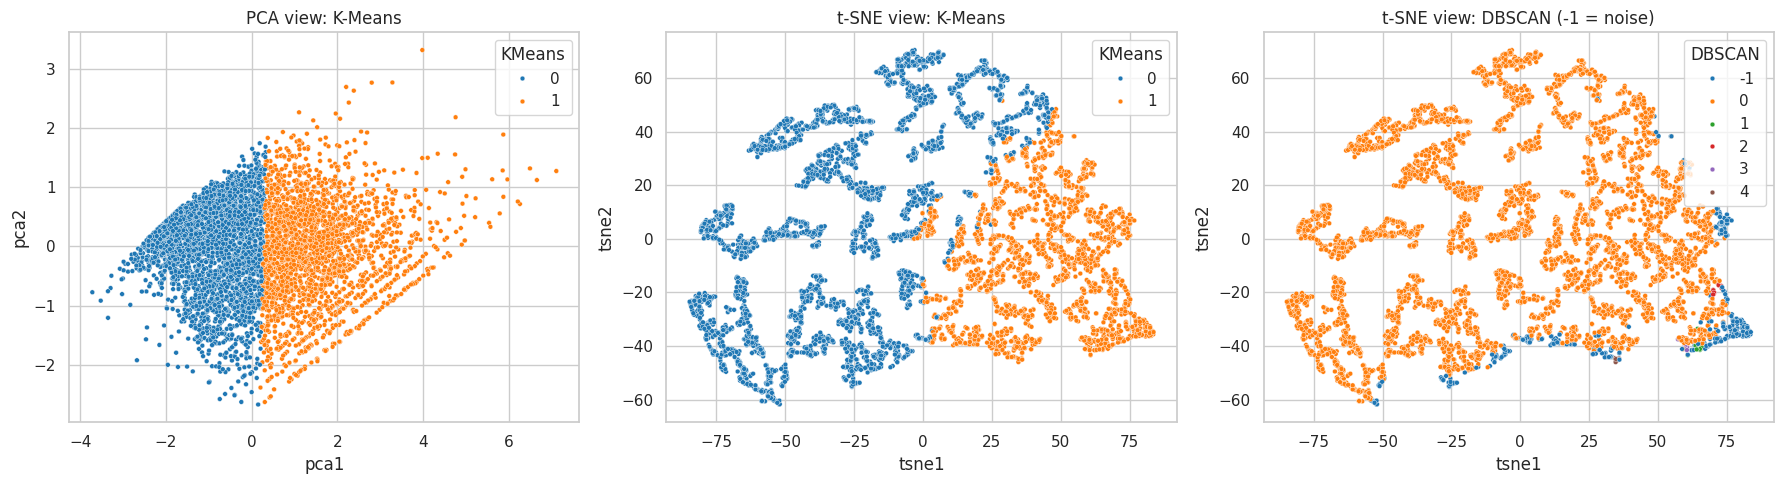

In [ ]:
tsne = TSNE(n_components=2, perplexity=30, init="pca",
            learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)

rfm["tsne1"], rfm["tsne2"] = X_tsne[:, 0], X_tsne[:, 1]
rfm["pca1"], rfm["pca2"] = X_pca[:, 0], X_pca[:, 1] if X_pca.shape[1] > 1 else 0

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=rfm, x="pca1", y="pca2", hue="KMeans", palette="tab10", s=12, ax=axes[0]).set_title("PCA view: K-Means")
sns.scatterplot(data=rfm, x="tsne1", y="tsne2", hue="KMeans", palette="tab10", s=12, ax=axes[1]).set_title("t-SNE view: K-Means")
sns.scatterplot(data=rfm, x="tsne1", y="tsne2", hue="DBSCAN", palette="tab10", s=12, ax=axes[2]).set_title("t-SNE view: DBSCAN (-1 = noise)")
plt.tight_layout(); plt.show()

In [ ]:
profile = rfm.groupby("KMeans").agg(
    Customers=("Recency", "size"),
    Recency_median=("Recency", "median"),
    Frequency_median=("Frequency", "median"),
    Monetary_median=("Monetary", "median"),
    Monetary_total=("Monetary", "sum"),
).round(1)

profile["% of Customers"] = (100 * profile["Customers"] / profile["Customers"].sum()).round(1)
profile["% of Revenue"] = (100 * profile["Monetary_total"] / profile["Monetary_total"].sum()).round(1)
profile

,Customers,Recency_median,Frequency_median,Monetary_median,Monetary_total,% of Customers,% of Revenue
KMeans,,,,,,,
0,3567,289.0,2.0,423.8,2250878.4,60.7,12.7
1,2311,23.0,8.0,2919.8,15492550.8,39.3,87.3


In [ ]:
overall = rfm[["Recency", "Frequency", "Monetary"]].median()

def name_persona(row):
    recent = row["Recency_median"] <= overall["Recency"]
    frequent = row["Frequency_median"] >= overall["Frequency"]
    big = row["Monetary_median"] >= overall["Monetary"]

    if recent and frequent and big:
        return "Champions"
    if frequent and big and not recent:
        return "At-Risk Loyalists"
    if recent and not frequent:
        return "New / Promising"
    if big and not frequent:
        return "Big-Ticket Occasionals"
    if not recent and not frequent and not big:
        return "Hibernating / Lost"
    return "Regular Shoppers"

actions = {
    "Champions": "VIP tier, early access to launches, referral rewards. Avoid blanket discounts.",
    "At-Risk Loyalists": "Win-back campaign: 'We miss you' email, personalised offer, check satisfaction.",
    "New / Promising": "Onboarding series, second-purchase incentive, cross-sell complementary items.",
    "Big-Ticket Occasionals": "Premium bundles, restock reminders, free shipping thresholds to raise frequency.",
    "Hibernating / Lost": "Low-cost reactivation (one last coupon), then suppress to save marketing spend.",
    "Regular Shoppers": "Loyalty points, bundle deals, seasonal campaigns to nudge frequency up.",
}

profile["Persona"] = profile.apply(name_persona, axis=1)
profile["Recommended Action"] = profile["Persona"].map(actions)
rfm["Persona"] = rfm["KMeans"].map(profile["Persona"])

pd.set_option("display.max_colwidth", None)
profile[["Customers", "% of Customers", "% of Revenue", "Recency_median",
         "Frequency_median", "Monetary_median", "Persona", "Recommended Action"]]

,Customers,% of Customers,% of Revenue,Recency_median,Frequency_median,Monetary_median,Persona,Recommended Action
KMeans,,,,,,,,
0,3567,60.7,12.7,289.0,2.0,423.8,Hibernating / Lost,"Low-cost reactivation (one last coupon), then suppress to save marketing spend."
1,2311,39.3,87.3,23.0,8.0,2919.8,Champions,"VIP tier, early access to launches, referral rewards. Avoid blanket discounts."


In [ ]:
rfm[["Recency", "Frequency", "Monetary", "KMeans", "Persona"]].to_csv("customer_segments.csv")